# Лабораторная работа 4. Поиск подстроки

**Опора:** лекция 7.

Реализуются **три алгоритма поиска**: наивный, Кнута–Морриса–Пратта и
Рабина–Карпа. Задача у всех трёх одна.

- **Вход:** текст и образец.
- **Выход:** список позиций начала всех вхождений образца в текст, в порядке
  возрастания, включая перекрывающиеся вхождения. Если вхождений нет — пустой
  список.

```text
Вход:  текст = "ababa", образец = "aba"      Выход: [0, 2]
Вход:  текст = "abcdef", образец = "xyz"     Выход: []
```

Пустой образец считается входящим в каждую позицию, включая позицию за концом
текста: для текста длины `n` ответ — `[0, 1, …, n]`.

Тексты, образцы, измерение времени и графики уже готовы и
лежат в пакете `labkit` рядом с ноутбуком.

In [23]:
import sys
from pathlib import Path

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "labkit").is_dir():
        sys.path.insert(0, str(candidate))
        break

import labkit as lk

print("Режим:", lk.CONFIG.name, "| длины текстов:", lk.text_sizes())

Режим: быстрый | длины текстов: [2000, 4000, 8000, 16000, 32000]


## Задача 1. Наивный поиск

Образец прикладывается к каждой позиции текста и сравнивается посимвольно.

In [24]:
def naive_search(text, pattern):
    """Список позиций всех вхождений pattern в text, включая перекрывающиеся."""
    # TODO: реализовать наивный поиск
    
    resultList = []

    # if len(pattern) == 0:
    #     return list(range(len(text) + 1))

    for i in range(len(text) - len(pattern) + 1):
        flag = True
        for j in range(len(pattern)):
            if text[i + j] != pattern[j]:
                flag = False
                break
        if flag:
            resultList.append(i)

    return resultList

    raise NotImplementedError("naive_search")

In [25]:
lk.check_search(naive_search, "Наивный поиск")

Наивный поиск
  [ok]   пустой текст и образец
    Input: {'pattern': '', 'text': ''}
    Output: [0]
    Expected: [0]
  [ok]   пустой текст
    Input: {'pattern': 'a', 'text': ''}
    Output: []
    Expected: []
  [ok]   пустой образец
    Input: {'pattern': '', 'text': 'abc'}
    Output: [0, 1, 2, 3]
    Expected: [0, 1, 2, 3]
  [ok]   один символ найден
    Input: {'pattern': 'a', 'text': 'a'}
    Output: [0]
    Expected: [0]
  [ok]   один символ не найден
    Input: {'pattern': 'b', 'text': 'a'}
    Output: []
    Expected: []
  [ok]   в начале
    Input: {'pattern': 'abc', 'text': 'abcdef'}
    Output: [0]
    Expected: [0]
  [ok]   в середине
    Input: {'pattern': 'cde', 'text': 'abcdef'}
    Output: [2]
    Expected: [2]
  [ok]   в конце
    Input: {'pattern': 'def', 'text': 'abcdef'}
    Output: [3]
    Expected: [3]
  [ok]   образец длиннее текста
    Input: {'pattern': 'abcdef', 'text': 'abc'}
    Output: []
    Expected: []
  [ok]   несколько вхождений
    Input: {'pattern

## Задача 2. Алгоритм Кнута–Морриса–Пратта

Отдельно вычисляется префикс-функция образца: для каждого префикса — длина его
наибольшего собственного суффикса, который одновременно является его префиксом.
При несовпадении поиск использует префикс-функцию и не возвращается назад по
тексту.

```text
Вход префикс-функции:  "ababa"    Выход: [0, 0, 1, 2, 3]
```

In [44]:
def prefix_function(pattern):
    """Для каждого префикса — длина наибольшего собственного суффикса,
    который одновременно является его префиксом."""
    # TODO: реализовать

    prefixTable = [0] * len(pattern)
    cursor = 0

    for i in range(1, len(pattern)):
        while cursor > 0 and pattern[i] != pattern[cursor]:
            cursor = prefixTable[cursor - 1]
        if pattern[i] == pattern[cursor]:
            cursor += 1
        prefixTable[i] = cursor

    return prefixTable


    raise NotImplementedError("prefix_function")


def kmp_search(text, pattern):
    """Список позиций всех вхождений pattern в text."""
    # TODO: реализовать поиск Кнута–Морриса–Пратта

    if len(text) == len(pattern) == 0: return [0]
    elif len(pattern) == 0: return list(range(len(text) + 1))
    elif len(text) == 0: return []

    prefixTable = prefix_function(pattern)
    resultList = []
    cursorText = 0
    cursorPattern = 0

    while cursorText < len(text):
        if text[cursorText] == pattern[cursorPattern]:
            cursorText += 1; cursorPattern += 1
            if cursorPattern == len(pattern):
                resultList.append(cursorText - cursorPattern)
                cursorPattern = prefixTable[cursorPattern - 1] 
        elif cursorPattern > 0:
            cursorPattern = prefixTable[cursorPattern - 1]
        else: cursorText += 1

    return(resultList)

    raise NotImplementedError("kmp_search")

In [45]:
lk.check_prefix_function(prefix_function)
lk.check_search(kmp_search, "Кнут–Моррис–Пратт")

Префикс-функция
  [ok]   префикс-функция
    Input: {'pattern': ''}
    Output: []
    Expected: []
  [ok]   префикс-функция
    Input: {'pattern': 'a'}
    Output: [0]
    Expected: [0]
  [ok]   префикс-функция
    Input: {'pattern': 'aaaa'}
    Output: [0, 1, 2, 3]
    Expected: [0, 1, 2, 3]
  [ok]   префикс-функция
    Input: {'pattern': 'abcd'}
    Output: [0, 0, 0, 0]
    Expected: [0, 0, 0, 0]
  [ok]   префикс-функция
    Input: {'pattern': 'ababa'}
    Output: [0, 0, 1, 2, 3]
    Expected: [0, 0, 1, 2, 3]
  [ok]   префикс-функция
    Input: {'pattern': 'aabaaab'}
    Output: [0, 1, 0, 1, 2, 2, 3]
    Expected: [0, 1, 0, 1, 2, 2, 3]
  [ok]   префикс-функция
    Input: {'pattern': 'abacabab'}
    Output: [0, 0, 1, 0, 1, 2, 3, 2]
    Expected: [0, 0, 1, 0, 1, 2, 3, 2]
  [ok]   200 случайных образцов
  Пройдено 8 из 8
Кнут–Моррис–Пратт
  [ok]   пустой текст и образец
    Input: {'pattern': '', 'text': ''}
    Output: [0]
    Expected: [0]
  [ok]   пустой текст
    Input: {'pattern':

## Задача 3. Алгоритм Рабина–Карпа

Сравниваются хеши образца и окна текста той же длины. Хеш здесь тот же
полиномиальный, что и у строковых ключей хеш-таблицы, — схема Горнера с
основанием `X` и модулем `q`:

```text
h = 0
для каждого символа c: h = (h * X + ord(c)) mod q
```

Отличие в том, что для каждого следующего окна хеш не вычисляется заново, а
пересчитывается за `O(1)` при сдвиге на один символ: из хеша вычитается вклад
ушедшего символа, остаток умножается на основание, прибавляется код пришедшего.
Такой хеш называется скользящим. Основание берётся не меньше размера алфавита,
модуль — большое простое число.

- **Требование:** при совпадении хешей обязательна проверка реального совпадения
  строк, поскольку возможны коллизии.

In [69]:
X = 33
MODULUS = 31

def rabin_karp_search(text, pattern):
    """Список позиций всех вхождений pattern в text."""
    # TODO: реализовать поиск Рабина–Карпа

    if len(text) == len(pattern) == 0: return [0]
    elif len(pattern) == 0: return list(range(len(text) + 1))
    elif len(text) == 0: return []

    cursor = 0
    resultList = []
    textLength = len(text)
    patternLength = len(pattern)
    firstCharContrib = pow(X, patternLength - 1, MODULUS)

    patternHash = 0
    for char in pattern:
        patternHash = (patternHash * X + ord(char)) % MODULUS
    
    textHash = 0
    for char in text[:patternLength]:
        textHash = (textHash * X + ord(char)) % MODULUS

    while cursor < textLength - patternLength:
        if textHash == patternHash and text[cursor : cursor + patternLength] == pattern:
            resultList.append(cursor)
        
        textHash = (textHash - ord(text[cursor]) * firstCharContrib) % MODULUS
        textHash = (textHash * X + ord(text[cursor + patternLength])) % MODULUS
        cursor += 1
    else:
        if textHash == patternHash and text[cursor : cursor + patternLength] == pattern:
            resultList.append(cursor)

    return resultList

    raise NotImplementedError("rabin_karp_search")

In [70]:
lk.check_search(rabin_karp_search, "Рабин–Карп")

Рабин–Карп
  [ok]   пустой текст и образец
    Input: {'pattern': '', 'text': ''}
    Output: [0]
    Expected: [0]
  [ok]   пустой текст
    Input: {'pattern': 'a', 'text': ''}
    Output: []
    Expected: []
  [ok]   пустой образец
    Input: {'pattern': '', 'text': 'abc'}
    Output: [0, 1, 2, 3]
    Expected: [0, 1, 2, 3]
  [ok]   один символ найден
    Input: {'pattern': 'a', 'text': 'a'}
    Output: [0]
    Expected: [0]
  [ok]   один символ не найден
    Input: {'pattern': 'b', 'text': 'a'}
    Output: []
    Expected: []
  [ok]   в начале
    Input: {'pattern': 'abc', 'text': 'abcdef'}
    Output: [0]
    Expected: [0]
  [ok]   в середине
    Input: {'pattern': 'cde', 'text': 'abcdef'}
    Output: [2]
    Expected: [2]
  [ok]   в конце
    Input: {'pattern': 'def', 'text': 'abcdef'}
    Output: [3]
    Expected: [3]
  [ok]   образец длиннее текста
    Input: {'pattern': 'abcdef', 'text': 'abc'}
    Output: []
    Expected: []
  [ok]   несколько вхождений
    Input: {'pattern': 

## Набор реализованных алгоритмов

Дальше всё считается по тем реализациям, которые действительно написаны. Все три
должны давать одинаковый ответ на одних и тех же данных.

In [71]:
SEARCHES = lk.implemented_searches({
    "наивный": naive_search,
    "Кнут–Моррис–Пратт": kmp_search,
    "Рабин–Карп": rabin_karp_search,
})

print("В экспериментах участвуют:", ", ".join(SEARCHES))
lk.check_same_results(SEARCHES, lk.random_text(5_000), ["abc", "abcd", "zzz", "a"])

В экспериментах участвуют: наивный, Кнут–Моррис–Пратт, Рабин–Карп
Согласованность реализаций
  [ok]   образец 'abc'
  [ok]   образец 'abcd'
  [ok]   образец 'zzz'
  [ok]   образец 'a'
  Пройдено 4 из 4


## Эксперимент 1. Размер входа

Слева растёт длина текста при образце длины 20, взятом из текста; справа
длина текста фиксирована, а растёт длина образца.

Размер входа: 100%|██████████| 30/30 [00:01<00:00, 18.29опыт/s]


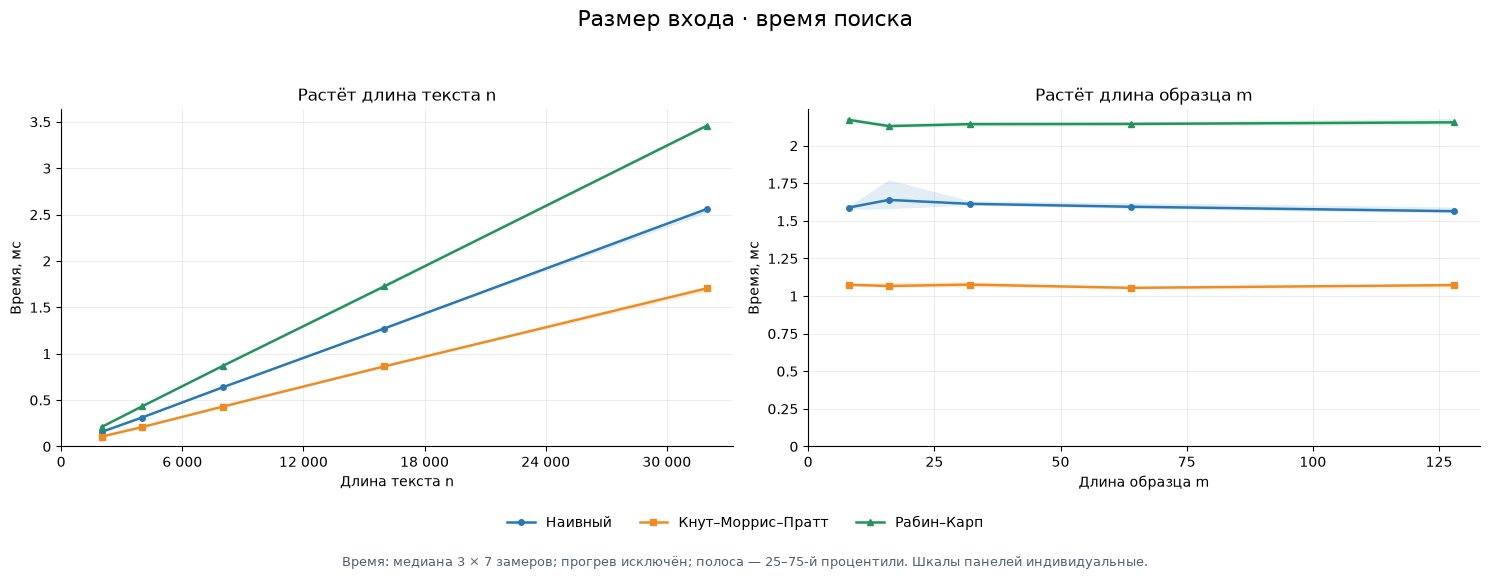

In [72]:
by_size = lk.size_experiment(SEARCHES)
lk.plot_search_experiment(by_size, "Размер входа · время поиска");

## Эксперимент 2. Масштабирование алгоритмов

Длины текста `n` и образца `m` удваиваются одновременно, причём во всех точках
`m = n / 10`. Алгоритмы проверяются на случайном тексте, на входе, где
несовпадение находится примерно после ¾ образца, и на тексте с большим числом
вхождений.

Каждый столбец соответствует алгоритму. Сверху показано медианное время поиска,
снизу — то же время, делённое на суммарную длину входа `n + m`. Полоса вокруг
линии показывает интервал от первого до третьего квартиля.

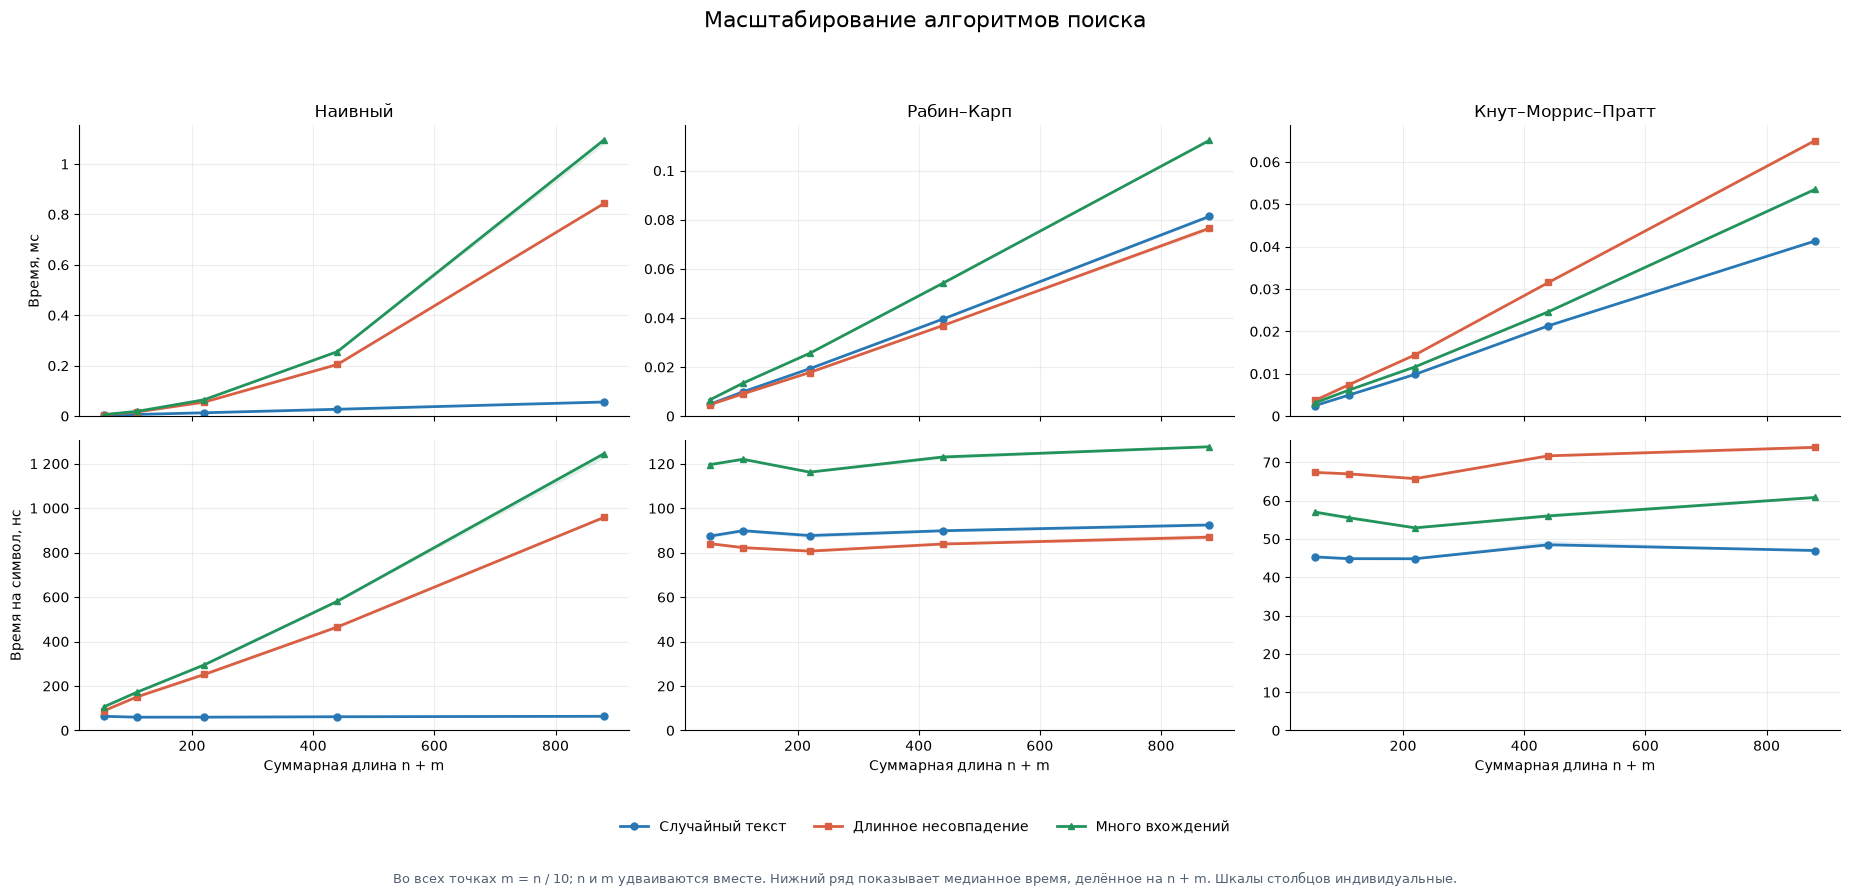

In [73]:
scaling = lk.scaling_experiment(SEARCHES)
lk.plot_scaling(scaling);

## Самостоятельные выводы

1. Почему увеличение длины текста и длины образца по-разному влияет на время
   поиска? Учтите число проверяемых окон `n − m + 1` и предварительную обработку
   образца.
- рост длины текста всегда будет давать линию, т.к. какой бы мы алгоритм не выбрали нам нужно будет пробираться по всем возможным позициям начала совпадений, что естественно растёт с длинной изнач. текста. Длина образца влияет чуть по разному в зависимости от алгоритма, но всё равно сводится к константе. В наивном поиске нам приходится сравнивать отрезуи больше по размеру с ростом m но при этом количество проходов снижается тоже на линию n/n = 1. В КНП мы проходимся по отрезку один раз и дальше просто работаем с таблицей доставая из неё элементы по индексу, что константно. В Рабин-Карпе мы вычисляем хэш образца единожды и только сравниваем в моменты попадания, так что армотизированная константа.
Из предварительной обработки везде по условию проверяю пустые паттерны, пустой текст и их вместе, из-за чего не приходиться возиться по всему массиву в подобных случаях.
2. Почему на случайном тексте наивный поиск может быть сопоставим с КМП и
   Рабином–Карпом, а на входе с длинным несовпадением начинает заметно
   проигрывать?
- наивный поиск сопоставим с линейным на массиве, и причины замедления такие же - чем длиннее несовпадение, тем больше проверяем, в добавок мы можем пройти m-1 элементов и обломаться на последнем, и тогда вернёмся в начало сравнения, что даёт небольшой n^2, просто с малым коэфициентом. При этом в КНП и РК мы тоже больше проверяем, но либо скипаем большие куски при КНП либо ходим константно и делаем одну проверку за раз в РК. На самом деле не могу сказать, что он начинает проигрывать именно на длиннм несовпадении, т.к. и на "много вхождений" тоже страдает, и впринципе как алгоритм он достаточно медленный. Их графики сравнимы на рандомных тестах, потому что в дикой природе нечасто попадаются ультра удобные совпадения суфиксов-префиксов, что замедляет КНП, а с РК мы постоянно проводим дополнительные математические операции для хэширования и на коллизиях тратим время сравнивая строки как в наивном
3. Как префикс-функция помогает КМП не возвращаться назад по тексту и находить
   перекрывающиеся вхождения?
- когда мы находим вхождение  или проваливаемся, мы уже знаем из таблицы префиксов, что суффикс наибольшей длины, позицию которого мы знаем и храним при итерировании - префикс образца, а значит мы можем начинать с начала этого суффикса-префикса, индекс которого мы знаем. Насколько это сократит зависит от количества удобных совпадений, но даже с рандомными данными это поможет срезать некоторые проходы.
4. Как скользящий хеш позволяет Рабину–Карпу обрабатывать следующее окно за
   `O(1)` и почему при совпадении хешей всё равно необходимо сравнивать строки?
- т.к. мы использзуем скользящий хэш, нам не приходится его перевычислять полностью, мы знаем начальный индекс и новый индекс, обращаемся к ним за конст. и проводим операции не зависящие от размера данных. Из-за жтого мы проходим на след. окно за O(1). При совпадении хешей мы перепроверяем обычной проверкой, т.к. возможны коллизии, хеши быстрее сравнения за счёт отбрасывания информации, но из-за неполной информации могут дать один хеш разным ключам.
5. Какие результаты графиков объясняются асимптотикой алгоритмов, а какие —
   устройством конкретных входов и постоянными затратами реализации на
   Python?
- асимптотикой алгор. объясняются формы графиков, а коэфициенты и константые добавки объясняются реализацией функцией мной (всеразличные условия, оптимизации или их отсутствия и т.п.) и работой python, тем, как он работает с памятью, насколько быстро выполняет код, как компьютер стартует без разогрева и т.д.